In [177]:
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
import numpy as np
from IPython.display import display

In [178]:
data = pd.read_pickle("clean_data.pkl")

# Task 1 - Explorativní analýza

# 1. Prozkoumáme jednotlívé sloupce a jejich typy

Po načtení vidíme, že některá data se opakují. Nejsme z toho prekvapení - v `task_0` byli jsme informování o duplikacích dat vůči sloupci `color`. 

**Naše interpretace dat**: opakující se a lišící se jenom barvou řádky jsou samostatné entity - stejně jako uvidíte zboží v obchodě; budou tedy interpretovány bez např. `groupby()` 



In [179]:

def print_with_end(data, end="\n\n"):
    print(data, end=end)
print_with_end(data.info())
display(data.head(3))
print_with_end(data["url"].value_counts())
print_with_end(data["name"].value_counts())
print_with_end(data["price"].describe())
print_with_end(data["brand"].value_counts())
print_with_end(data["motor_power_w"].describe())
print_with_end(data["battery_capacity_wh"].describe())
print_with_end(data["range_km"].describe())
print_with_end(data["speed_kmh"].describe())
print_with_end(data["color"].value_counts())


<class 'pandas.DataFrame'>
RangeIndex: 334 entries, 0 to 333
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype   
---  ------               --------------  -----   
 0   url                  334 non-null    str     
 1   name                 334 non-null    str     
 2   price                331 non-null    float64 
 3   brand                306 non-null    category
 4   motor_power_w        331 non-null    float64 
 5   battery_capacity_wh  172 non-null    float64 
 6   range_km             331 non-null    float64 
 7   speed_kmh            331 non-null    float64 
 8   color                196 non-null    category
dtypes: category(2), float64(5), str(2)
memory usage: 19.7 KB
None



,url,name,price,brand,motor_power_w,battery_capacity_wh,range_km,speed_kmh,color
0,https://www.geekbuying.com/item/Ausom-L1-Elect...,"Ausom L1 Electric Scooter, 800W Motor, 48V 15....",10656.98,ausom,500.0,998.4,90.0,20.0,NaN
1,https://www.geekbuying.com/item/Kukirin-G2-Fol...,Kukirin G2 Foldable Electric Scooter 2026 Upgr...,11870.77,kukirin,800.0,NaN,55.0,45.0,NaN
2,https://www.geekbuying.com/item/BOYUEDA-Q7-Pro...,"BOYUEDA Q7 Pro Max Electric Scooter, 1600W*2 M...",18910.69,boyueda,3200.0,1456.0,100.0,70.0,NaN


url
https://www.geekbuying.com/item/PVY-Z20-Plus-E-Bike-20-inch-Tires-48V-1000W-16-5Ah-50km-h-Speed-Khaki-521186.html    4
https://www.geekbuying.com/item/PVY-Z20-Plus-E-Bike-20-inch-Tires-48V-1000W-16-5Ah-50km-h-Speed-Grey-521185.html     4
https://www.geekbuying.com/item/ONESPORT-OT16-Electric-Bike-20-inch-Fat-Tire-17Ah-Battery-Black-523891.html          2
https://www.geekbuying.com/item/Kugoo-LX9-Electric-Scooter-2-650W-Motor-48V-18-2Ah-528696.html                       2
https://www.geekbuying.com/item/TWOFISH-V2-MAX-Electric-Scooter-800W-48V-20Ah-530740.html                            2
                                                                                                                    ..
https://www.geekbuying.com/item/TWOFISH-M5-ELITE-Electric-Scooter-500W-48V-13Ah-45km-h-531099.html                   1
https://www.geekbuying.com/item/Magicycle-Ocelot-Pro-2-0-Electric-Bike-Green-528323.html                             1
https://www.geekbuying.com/item/Magicycle-Cr

# 2. Zobrazíme rozložení dat, zinterpretujeme

 2.1
- Vybrali jsme `boxplot` a zvlášť `histogram` místo `violin plot` pro stručnou ale informativní zprávu.
- Vypsali ty nejdůležitější hodnoty rozsahu - kvartily a min/max hodnoty
- Pozorujeme některá anomální data, později se jich chceme zbavit

2.2
- Vypsali korelace parametrů - podívali jsme se na to graficky (`scatterplot`) a číselně (`heat map`). 
- Pozorujeme jak ajumulátor ovlivňuje všechno ostatní - cenu, výkon, délku jízdy a rychlost vozidla.

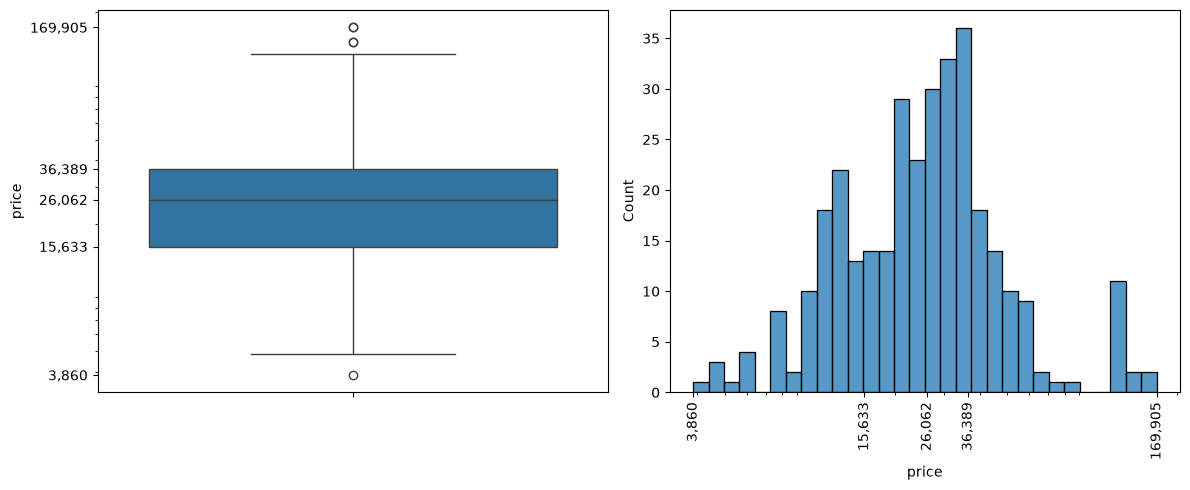

d:\main-folder\MASTERS\UPA\UPA-preparing\.venv\Lib\site-packages\matplotlib\scale.py:263: RuntimeWarning: invalid value encountered in log1p
  return self._forward(values)
d:\main-folder\MASTERS\UPA\UPA-preparing\.venv\Lib\site-packages\matplotlib\scale.py:263: RuntimeWarning: invalid value encountered in log1p
  return self._forward(values)


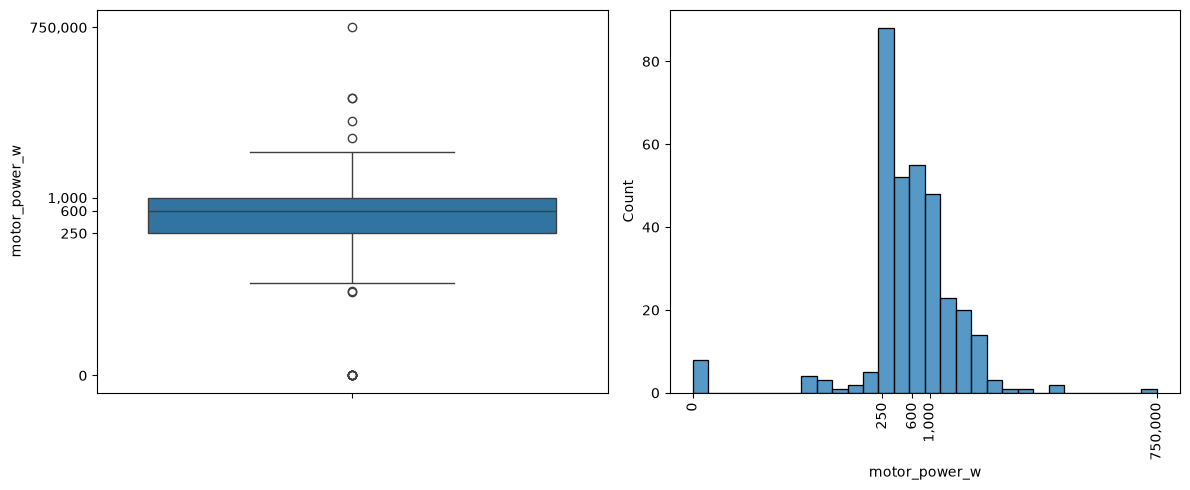

d:\main-folder\MASTERS\UPA\UPA-preparing\.venv\Lib\site-packages\matplotlib\scale.py:263: RuntimeWarning: invalid value encountered in log1p
  return self._forward(values)


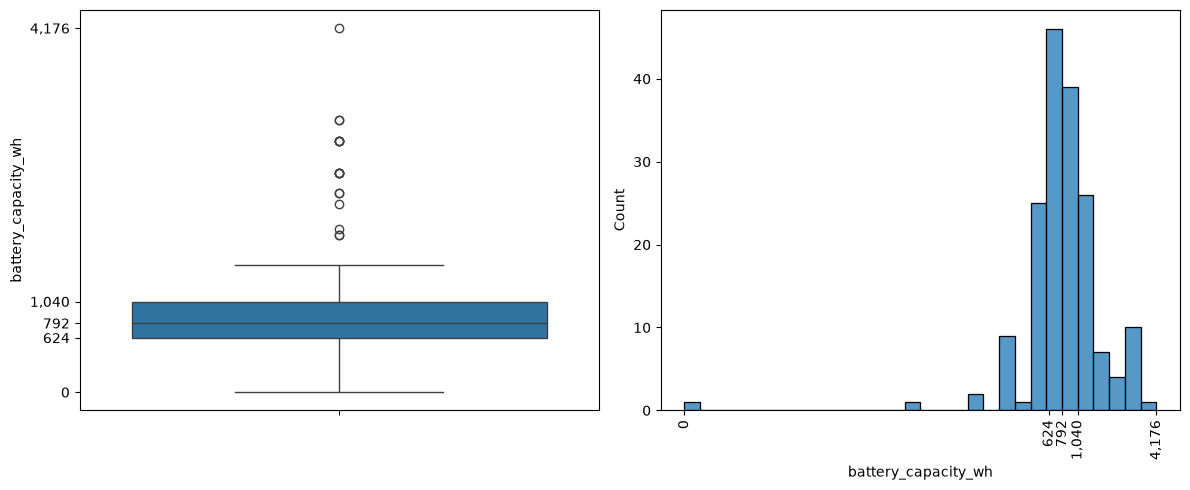

d:\main-folder\MASTERS\UPA\UPA-preparing\.venv\Lib\site-packages\matplotlib\scale.py:263: RuntimeWarning: invalid value encountered in log1p
  return self._forward(values)
d:\main-folder\MASTERS\UPA\UPA-preparing\.venv\Lib\site-packages\matplotlib\scale.py:263: RuntimeWarning: invalid value encountered in log1p
  return self._forward(values)


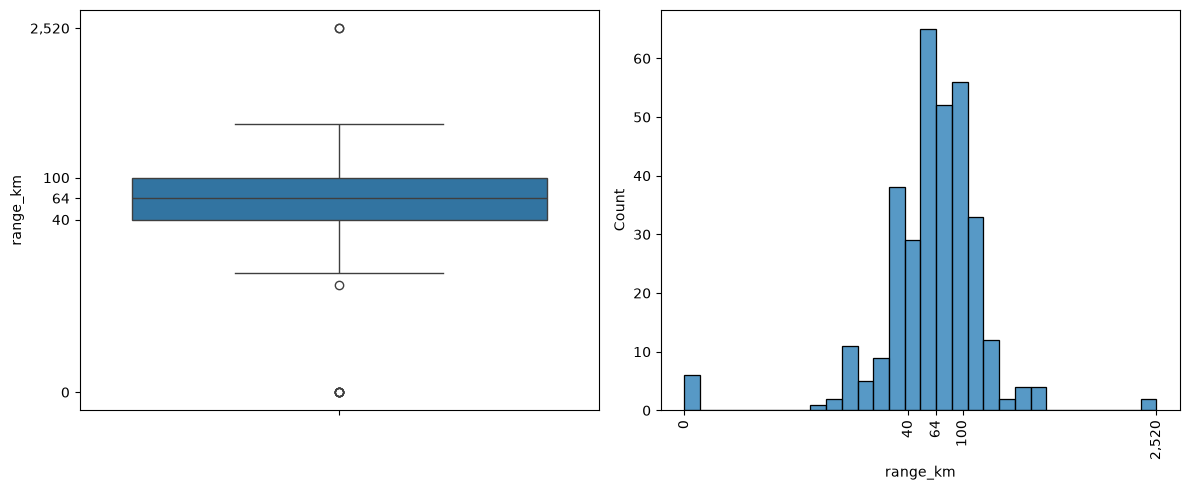

d:\main-folder\MASTERS\UPA\UPA-preparing\.venv\Lib\site-packages\matplotlib\scale.py:263: RuntimeWarning: invalid value encountered in log1p
  return self._forward(values)
d:\main-folder\MASTERS\UPA\UPA-preparing\.venv\Lib\site-packages\matplotlib\scale.py:263: RuntimeWarning: invalid value encountered in log1p
  return self._forward(values)


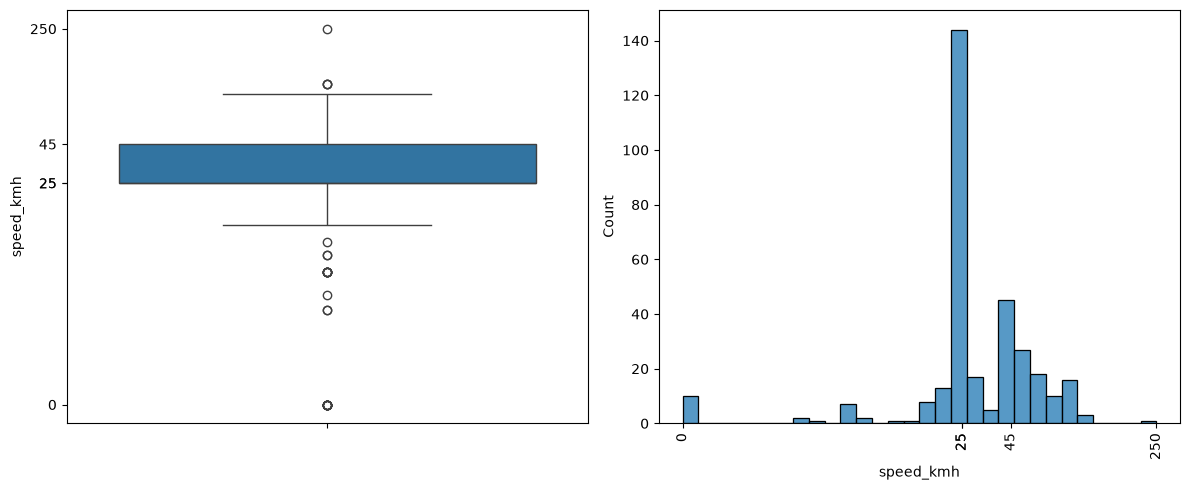

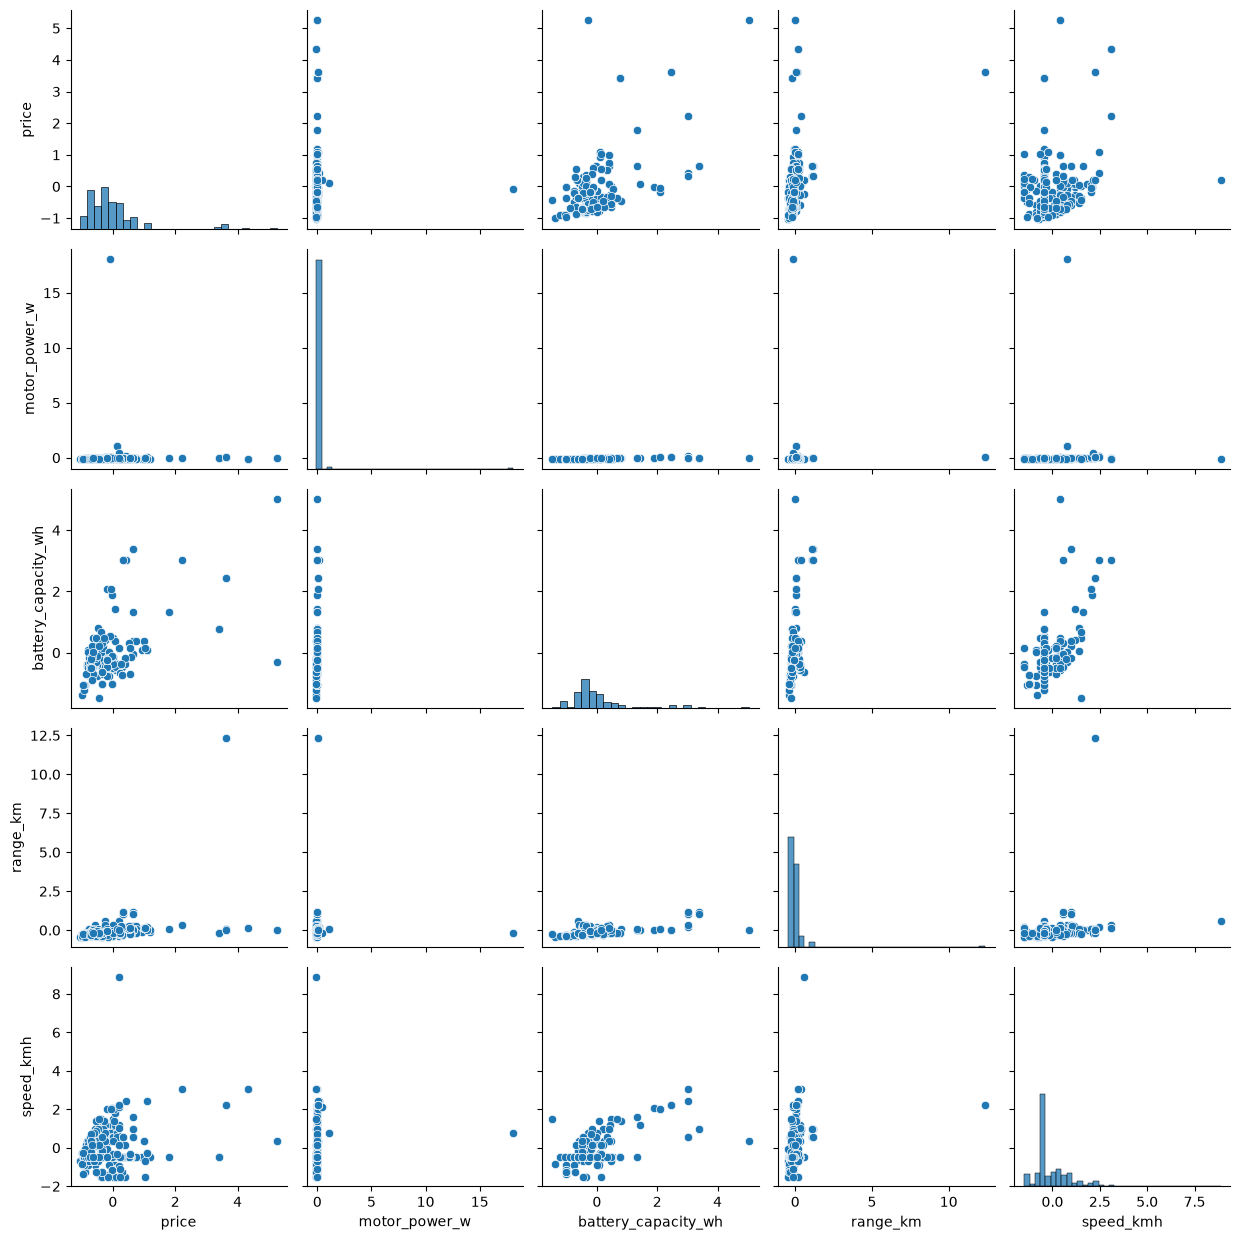

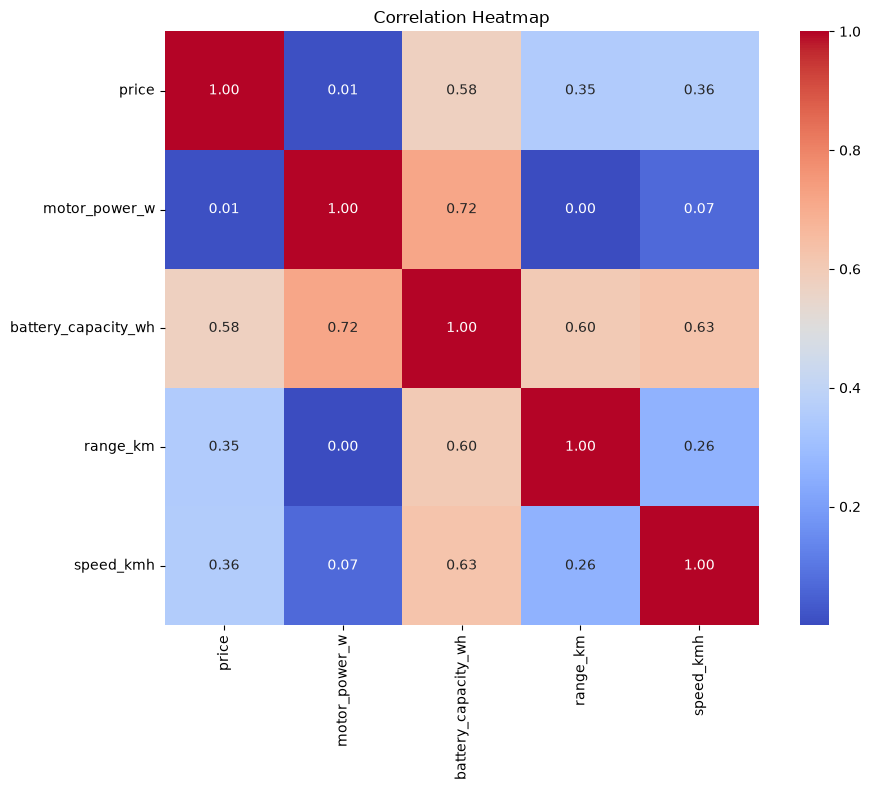

In [180]:

def plot_price_distribution(data):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    price = data["price"].dropna()

    axes[0].set_yscale("log")
    sns.boxplot(y=price, ax=axes[0])
    price_ticks = price.describe()[["min", "25%", "50%", "75%", "max"]].to_numpy()
    axes[0].set_yticks(price_ticks)
    axes[0].set_yticklabels([f"{value:,.0f}" for value in price_ticks])

    axes[1].set_xscale("log")
    sns.histplot(x=price, bins=30, ax=axes[1])
    axes[1].set_xticks(price_ticks)
    axes[1].set_xticklabels([f"{value:,.0f}" for value in price_ticks])
    axes[1].tick_params(axis="x", labelrotation=90)

    fig.tight_layout()
    plt.show()

def plot_motor_power_distribution(data):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    motor_power = data["motor_power_w"].dropna()

    axes[0].set_yscale("function", functions=(np.log1p, np.expm1))
    sns.boxplot(y=motor_power, ax=axes[0])
    power_ticks = motor_power.describe()[["min", "25%", "50%", "75%", "max"]].to_numpy()
    axes[0].set_yticks(power_ticks)
    axes[0].set_yticklabels([f"{value:,.0f}" for value in power_ticks])

    axes[1].set_xscale("function", functions=(np.log1p, np.expm1))
    sns.histplot(x=motor_power, bins=30, ax=axes[1])
    axes[1].set_xticks(power_ticks)
    axes[1].set_xticklabels([f"{value:,.0f}" for value in power_ticks])
    axes[1].tick_params(axis="x", labelrotation=90)

    fig.tight_layout()
    plt.show()

def plot_battery_capacity_distribution(data):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    capacity = data["battery_capacity_wh"].dropna()

    sns.boxplot(y=capacity, ax=axes[0])
    capacity_ticks = capacity.describe()[["min", "25%", "50%", "75%", "max"]].to_numpy()
    axes[0].set_yticks(capacity_ticks)
    axes[0].set_yticklabels([f"{value:,.0f}" for value in capacity_ticks])

    axes[1].set_xscale("function", functions=(np.log1p, np.expm1))
    sns.histplot(x=capacity, bins=30, ax=axes[1])
    axes[1].set_xticks(capacity_ticks)
    axes[1].set_xticklabels([f"{value:,.0f}" for value in capacity_ticks])
    axes[1].tick_params(axis="x", labelrotation=90)

    fig.tight_layout()
    plt.show()

def plot_range_distribution(data):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    range_km = data["range_km"].dropna()

    axes[0].set_yscale("function", functions=(np.log1p, np.expm1))
    sns.boxplot(y=range_km, ax=axes[0])
    range_ticks = range_km.describe()[["min", "25%", "50%", "75%", "max"]].to_numpy()
    axes[0].set_yticks(range_ticks)
    axes[0].set_yticklabels([f"{value:,.0f}" for value in range_ticks])

    axes[1].set_xscale("function", functions=(np.log1p, np.expm1))
    sns.histplot(x=range_km, bins=30, ax=axes[1])
    axes[1].set_xticks(range_ticks)
    axes[1].set_xticklabels([f"{value:,.0f}" for value in range_ticks])
    axes[1].tick_params(axis="x", labelrotation=90)

    fig.tight_layout()
    plt.show()

def plot_speed_distribution(data):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    speed = data["speed_kmh"].dropna()

    axes[0].set_yscale("function", functions=(np.log1p, np.expm1))
    sns.boxplot(y=speed, ax=axes[0])
    speed_ticks = speed.describe()[["min", "25%", "50%", "75%", "max"]].to_numpy()
    axes[0].set_yticks(speed_ticks)
    axes[0].set_yticklabels([f"{value:,.0f}" for value in speed_ticks])

    axes[1].set_xscale("function", functions=(np.log1p, np.expm1))
    sns.histplot(x=speed, bins=30, ax=axes[1])
    axes[1].set_xticks(speed_ticks)
    axes[1].set_xticklabels([f"{value:,.0f}" for value in speed_ticks])
    axes[1].tick_params(axis="x", labelrotation=90)

    fig.tight_layout()
    plt.show()

def draw_n_by_n_scatterplot(data):
    numeric_columns = data.select_dtypes(include=[np.number]).columns
    # norm data for better visualization
    data_for_scatter = (data[numeric_columns] - data[numeric_columns].mean()) / data[numeric_columns].std()
    grid = sns.pairplot(data_for_scatter)
    plt.tight_layout()
    plt.show()

def draw_correlation_heatmap(data):
    numeric_columns = data.select_dtypes(include=[np.number]).columns
    correlation_matrix = data[numeric_columns].corr()
    plt.figure(figsize=(10, 8))
    sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", square=True)
    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.show()

plot_price_distribution(data)
plot_motor_power_distribution(data)
plot_battery_capacity_distribution(data)
plot_range_distribution(data)
plot_speed_distribution(data)
draw_n_by_n_scatterplot(data)
draw_correlation_heatmap(data)

# 3. Odlehlé hodnoty

Číselné odléhle hodnoty jsme lehce detekovalí s grafy rozložení - víme odkud pochází většína takových hodnot a je to nepřesnost LLM běhém skénování. Například `motor power` = 750000W místo 750W. `range` = 0km, což nemá smysl ani s marketingového pohledu

Stejným způsobem (`histogram`) se můžeme podívat i na kategorická data. V případě barev pozorujeme hodně jednotlivých - buď jsou nepopulární nebo LLM někdy preferuje lehčí variantu popisu

V případě značek - ta nejvíc rozprostřena je fafrees

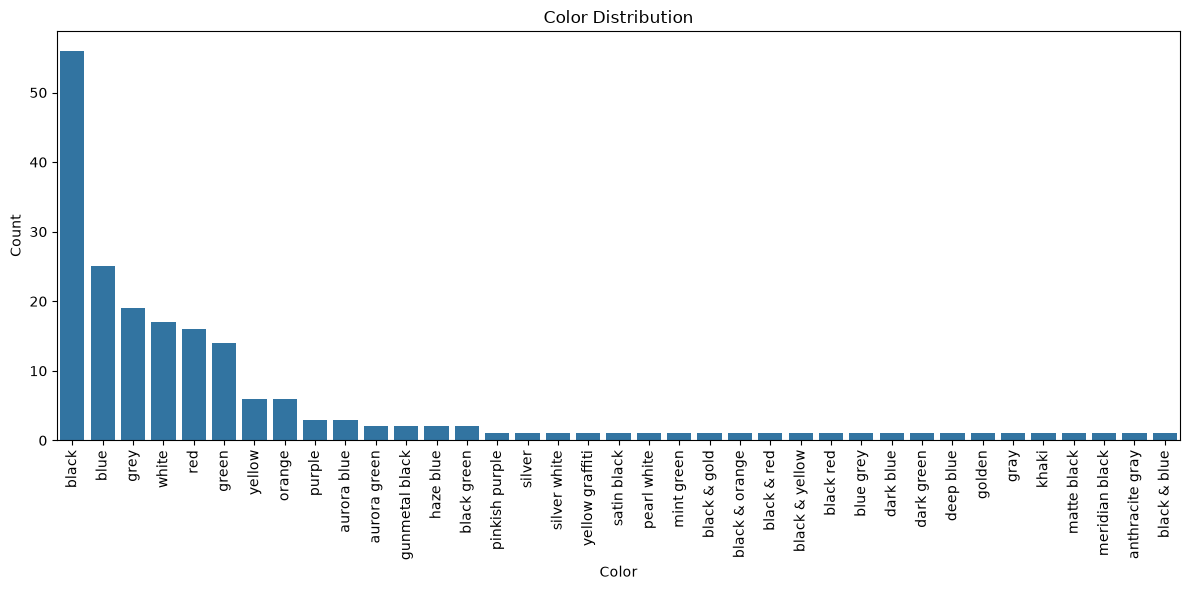

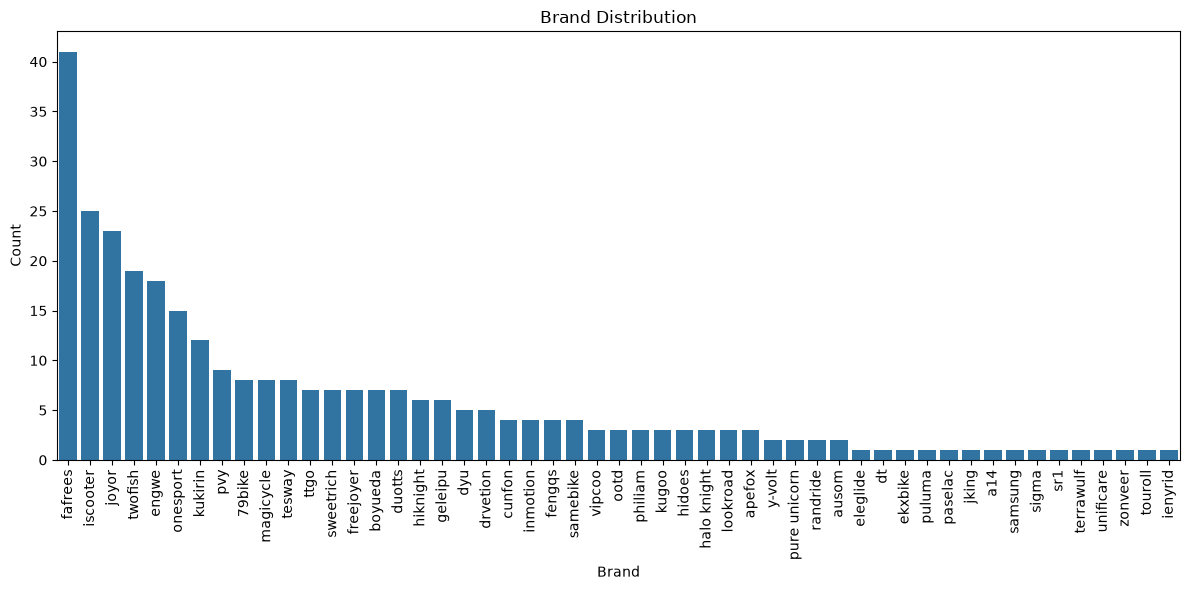

In [185]:
def plot_color_distribution(data):
    plt.figure(figsize=(12, 6))
    color_counts = data["color"].value_counts().sort_values(ascending=True)
    sns.barplot(
        x=color_counts.index,
        y=color_counts.values,
        order=list(reversed(color_counts.index)),
    )
    plt.xticks(rotation=90)
    plt.title("Color Distribution")
    plt.xlabel("Color")
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

def plot_brand_distribution(data):
    plt.figure(figsize=(12, 6))
    brand_counts = data["brand"].value_counts().sort_values(ascending=True)
    sns.barplot(
        x=brand_counts.index,
        y=brand_counts.values,
        order=list(reversed(brand_counts.index)),
    )
    plt.xticks(rotation=90)
    plt.title("Brand Distribution")
    plt.xlabel("Brand")
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

plot_color_distribution(data)
plot_brand_distribution(data)

# 4. Chybějící hodnoty

- zjistíme jaké procento null hodnot má každý sloupec; nejvíc má `battery_capacity_wh`, pak `color` a `brand`
- zjistíme jaké procento řádku má 1 až 9 null hodnot; některé dokonce mají 6 a 7, nebudou moc užitečné

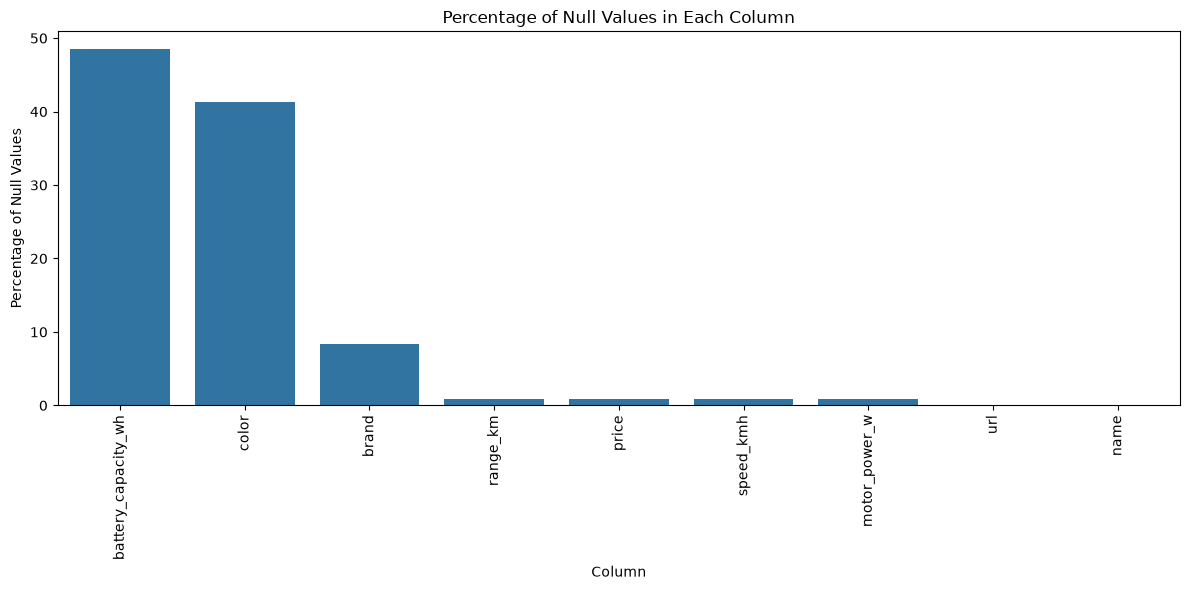

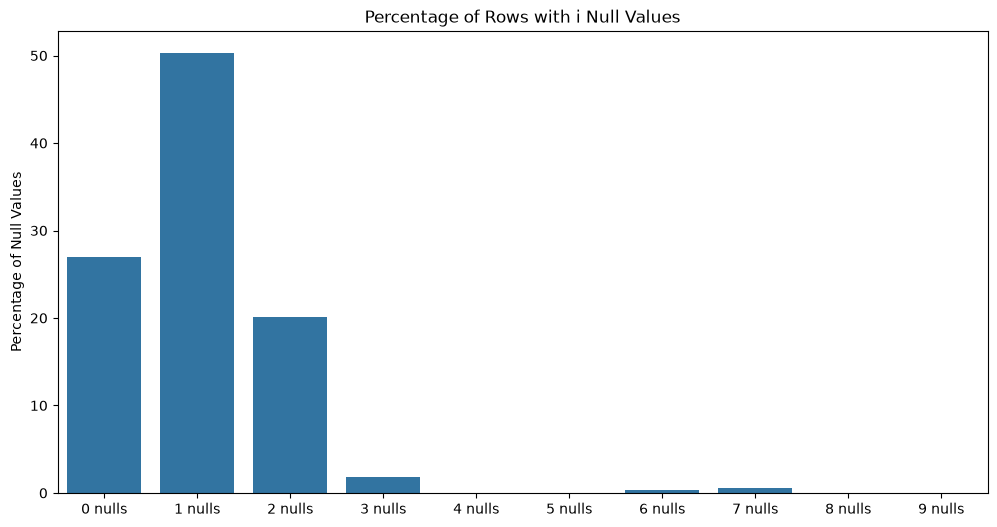

In [205]:
def plot_null_percentages_by_column(data):
    null_percentages = data.isnull().mean().mul(100).sort_values(ascending=False)
    plt.figure(figsize=(12, 6))
    sns.barplot(
        x=null_percentages.index,
        y=null_percentages.values,
        order=null_percentages.index,
    )
    plt.xticks(rotation=90)
    plt.title("Percentage of Null Values in Each Column")
    plt.xlabel("Column")
    plt.ylabel("Percentage of Null Values")
    plt.tight_layout()

def plot_row_null_percentages(data):
    # Calculate the percenttage of rows with i null values
    plt.figure(figsize=(12, 6))
    sns.barplot(
        x=[f"{i} nulls" for i in range(0, data.shape[1] + 1)],
        y=[(data.isnull().sum(axis=1) == i).mean() * 100 for i in range(0, data.shape[1] + 1)],
    ) 
    plt.title("Percentage of Rows with i Null Values")
    plt.ylabel("Percentage of Null Values")

plot_null_percentages_by_column(data)
plot_row_null_percentages(data)

# 5. Korelační analýza (viz. #2)

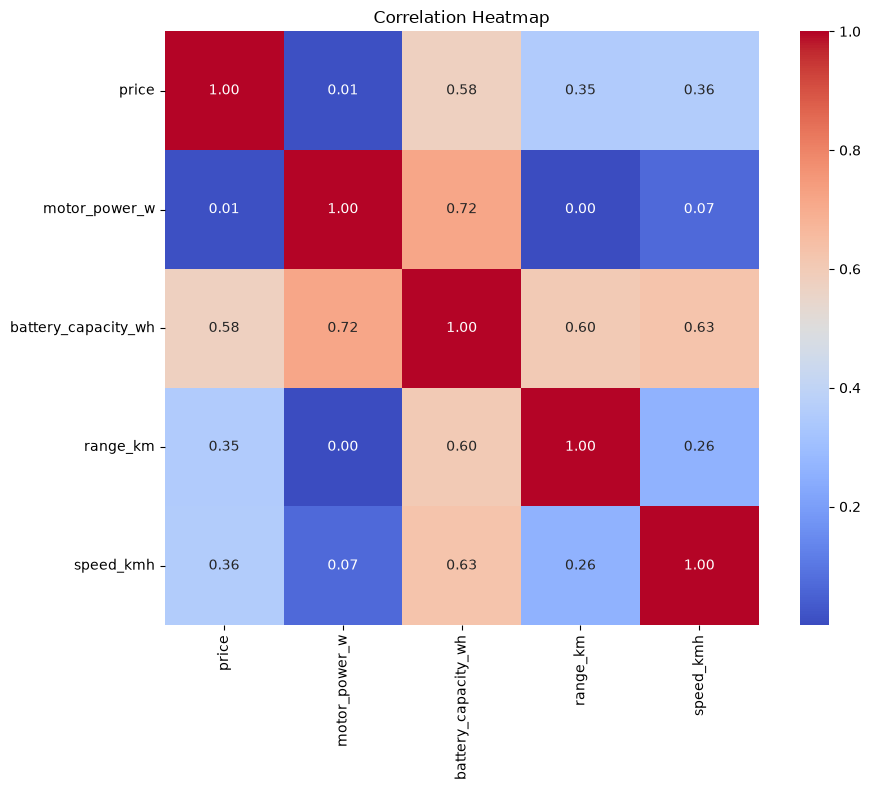

In [206]:
draw_correlation_heatmap(data)